In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

In [4]:
# Import both datasets

train = pd.read_csv("fraudTrain.csv")
test = pd.read_csv("fraudTest.csv")

print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

Training Dataset Shape: (1296675, 23)
Testing Dataset Shape: (555719, 23)


In [5]:
train.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [6]:
test.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


In [7]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1296675 entries, 0 to 1296674
Data columns (total 23 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Unnamed: 0             1296675 non-null  int64  
 1   trans_date_trans_time  1296675 non-null  object 
 2   cc_num                 1296675 non-null  int64  
 3   merchant               1296675 non-null  object 
 4   category               1296675 non-null  object 
 5   amt                    1296675 non-null  float64
 6   first                  1296675 non-null  object 
 7   last                   1296675 non-null  object 
 8   gender                 1296675 non-null  object 
 9   street                 1296675 non-null  object 
 10  city                   1296675 non-null  object 
 11  state                  1296675 non-null  object 
 12  zip                    1296675 non-null  int64  
 13  lat                    1296675 non-null  float64
 14  long              

In [8]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 555719 entries, 0 to 555718
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Unnamed: 0             555719 non-null  int64  
 1   trans_date_trans_time  555719 non-null  object 
 2   cc_num                 555719 non-null  int64  
 3   merchant               555719 non-null  object 
 4   category               555719 non-null  object 
 5   amt                    555719 non-null  float64
 6   first                  555719 non-null  object 
 7   last                   555719 non-null  object 
 8   gender                 555719 non-null  object 
 9   street                 555719 non-null  object 
 10  city                   555719 non-null  object 
 11  state                  555719 non-null  object 
 12  zip                    555719 non-null  int64  
 13  lat                    555719 non-null  float64
 14  long                   555719 non-nu

In [9]:
train.describe(include="all")

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
count,1.296675e+06,1296675,1.296675e+06,1296675,1296675,1.296675e+06,1296675,1296675,1296675,1296675,...,1.296675e+06,1.296675e+06,1.296675e+06,1296675,1296675,1296675,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
unique,NaN,1274791,NaN,693,14,NaN,352,481,2,983,...,NaN,NaN,NaN,494,968,1296675,NaN,NaN,NaN,NaN
top,NaN,2019-04-22 16:02:01,NaN,fraud_Kilback LLC,gas_transport,NaN,Christopher,Smith,F,864 Reynolds Plains,...,NaN,NaN,NaN,Film/video editor,1977-03-23,8f7c8e4ab7f25875d753b422917c98c9,NaN,NaN,NaN,NaN
freq,NaN,4,NaN,4403,131659,NaN,26669,28794,709863,3123,...,NaN,NaN,NaN,9779,5636,1,NaN,NaN,NaN,NaN
mean,6.483370e+05,NaN,4.171920e+17,NaN,NaN,7.035104e+01,NaN,NaN,NaN,NaN,...,3.853762e+01,-9.022634e+01,8.882444e+04,NaN,NaN,NaN,1.349244e+09,3.853734e+01,-9.022646e+01,5.788652e-03
std,3.743180e+05,NaN,1.308806e+18,NaN,NaN,1.603160e+02,NaN,NaN,NaN,NaN,...,5.075808e+00,1.375908e+01,3.019564e+05,NaN,NaN,NaN,1.284128e+07,5.109788e+00,1.377109e+01,7.586269e-02
min,0.000000e+00,NaN,6.041621e+10,NaN,NaN,1.000000e+00,NaN,NaN,NaN,NaN,...,2.002710e+01,-1.656723e+02,2.300000e+01,NaN,NaN,NaN,1.325376e+09,1.902779e+01,-1.666712e+02,0.000000e+00
25%,3.241685e+05,NaN,1.800429e+14,NaN,NaN,9.650000e+00,NaN,NaN,NaN,NaN,...,3.462050e+01,-9.679800e+01,7.430000e+02,NaN,NaN,NaN,1.338751e+09,3.473357e+01,-9.689728e+01,0.000000e+00
50%,6.483370e+05,NaN,3.521417e+15,NaN,NaN,4.752000e+01,NaN,NaN,NaN,NaN,...,3.935430e+01,-8.747690e+01,2.456000e+03,NaN,NaN,NaN,1.349250e+09,3.936568e+01,-8.743839e+01,0.000000e+00
75%,9.725055e+05,NaN,4.642255e+15,NaN,NaN,8.314000e+01,NaN,NaN,NaN,NaN,...,4.194040e+01,-8.015800e+01,2.032800e+04,NaN,NaN,NaN,1.359385e+09,4.195716e+01,-8.023680e+01,0.000000e+00


In [10]:
# Check column names

print("Training Columns:")
print(train.columns)

print("\nTesting Columns:")
print(test.columns)

Training Columns:
Index(['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud'],
      dtype='object')

Testing Columns:
Index(['Unnamed: 0', 'trans_date_trans_time', 'cc_num', 'merchant', 'category',
       'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
       'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time',
       'merch_lat', 'merch_long', 'is_fraud'],
      dtype='object')


In [11]:
# Check null values

print("Training Null Values:")
print(train.isnull().sum())

print("\nTesting Null Values:")
print(test.isnull().sum())

Training Null Values:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

Testing Null Values:
Unnamed: 0               0
trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    

In [12]:
# Check duplicate rows

print("Training Duplicate Rows:", train.duplicated().sum())
print("Testing Duplicate Rows:", test.duplicated().sum())

Training Duplicate Rows: 0
Testing Duplicate Rows: 0


In [13]:
# Check duplicate columns

print("Training Duplicate Columns:",
      train.columns[train.columns.duplicated()].tolist())

print("Testing Duplicate Columns:",
      test.columns[test.columns.duplicated()].tolist())

Training Duplicate Columns: []
Testing Duplicate Columns: []


In [14]:
# Fraud vs Non-Fraud Transactions

print("Training Data:")
print(train["is_fraud"].value_counts())

print("\nTesting Data:")
print(test["is_fraud"].value_counts())

Training Data:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

Testing Data:
is_fraud
0    553574
1      2145
Name: count, dtype: int64


In [15]:
# Check missing values

print(train.isnull().sum().sum())
print(test.isnull().sum().sum())

0
0


In [16]:
train = train.dropna()
test = test.dropna()

In [17]:
# Remove duplicate rows

train = train.drop_duplicates()
test = test.drop_duplicates()

In [18]:
# Drop unwanted columns

unwanted_columns = [
    "Unnamed: 0",
    "trans_date_trans_time",
    "cc_num",
    "first",
    "last",
    "street",
    "city",
    "state",
    "zip",
    "dob",
    "trans_num"
]

train = train.drop(columns=unwanted_columns, errors="ignore")
test = test.drop(columns=unwanted_columns, errors="ignore")

In [19]:
print(train.columns)

Index(['merchant', 'category', 'amt', 'gender', 'lat', 'long', 'city_pop',
       'job', 'unix_time', 'merch_lat', 'merch_long', 'is_fraud'],
      dtype='object')


In [20]:
categorical_columns = train.select_dtypes(include="object").columns

print(categorical_columns)

Index(['merchant', 'category', 'gender', 'job'], dtype='object')


In [21]:
# Encode categorical features

for column in categorical_columns:
    
    encoder = LabelEncoder()
    
    combined_values = pd.concat(
        [train[column], test[column]],
        axis=0
    ).astype(str)
    
    encoder.fit(combined_values)
    
    train[column] = encoder.transform(
        train[column].astype(str)
    )
    
    test[column] = encoder.transform(
        test[column].astype(str)
    )

In [22]:
# Check processed training data

train.head()

,merchant,category,amt,gender,lat,long,city_pop,job,unix_time,merch_lat,merch_long,is_fraud
0,514,8,4.97,0,36.0788,-81.1781,3495,372,1325376018,36.011293,-82.048315,0
1,241,4,107.23,0,48.8878,-118.2105,149,431,1325376044,49.159047,-118.186462,0
2,390,0,220.11,1,42.1808,-112.2620,4154,308,1325376051,43.150704,-112.154481,0
3,360,2,45.00,1,46.2306,-112.1138,1939,330,1325376076,47.034331,-112.561071,0
4,297,9,41.96,1,38.4207,-79.4629,99,116,1325376186,38.674999,-78.632459,0


In [23]:
# Check processed testing data

test.head()

,merchant,category,amt,gender,lat,long,city_pop,job,unix_time,merch_lat,merch_long,is_fraud
0,319,10,2.86,1,33.9659,-80.9355,333497,288,1371816865,33.986391,-81.200714,0
1,591,10,29.84,0,40.3207,-110.4360,302,406,1371816873,39.450498,-109.960431,0
2,611,5,41.28,0,40.6729,-73.5365,34496,272,1371816893,40.495810,-74.196111,0
3,222,9,60.05,1,28.5697,-80.8191,54767,422,1371816915,28.812398,-80.883061,0
4,292,13,3.19,1,44.2529,-85.0170,1126,205,1371816917,44.959148,-85.884734,0


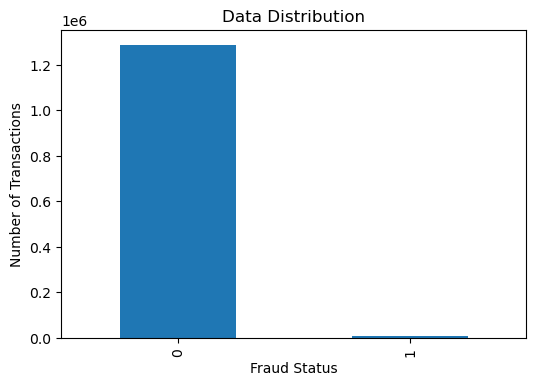

In [24]:
# Check Data Distribution

train["is_fraud"].value_counts().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Data Distribution")
plt.xlabel("Fraud Status")
plt.ylabel("Number of Transactions")
plt.show()

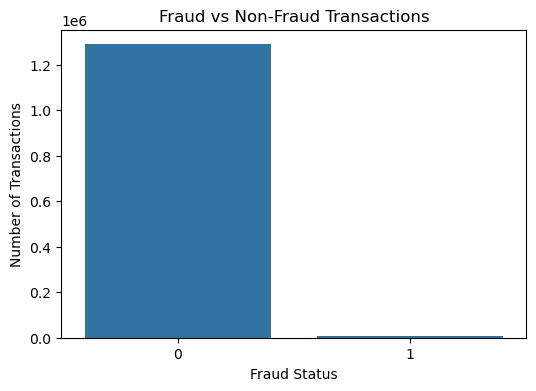

In [25]:
# Fraud vs Non-Fraud Transactions - Countplot

plt.figure(figsize=(6,4))

sns.countplot(
    x="is_fraud",
    data=train
)

plt.title("Fraud vs Non-Fraud Transactions")
plt.xlabel("Fraud Status")
plt.ylabel("Number of Transactions")
plt.show()

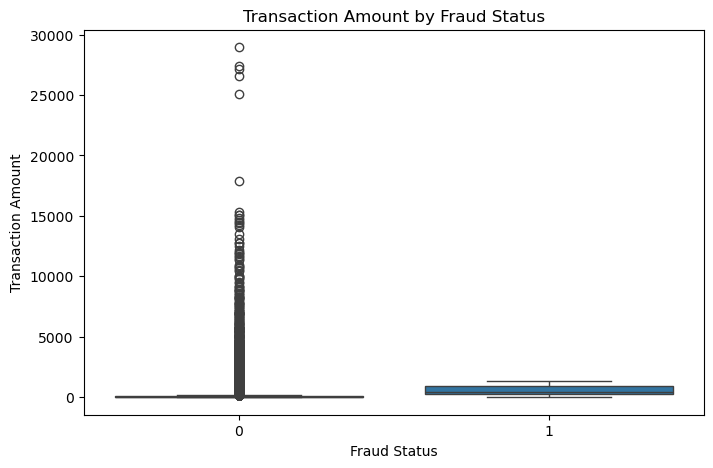

In [26]:
# Boxplot

plt.figure(figsize=(8,5))

sns.boxplot(
    x="is_fraud",
    y="amt",
    data=train
)

plt.title("Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Transaction Amount")
plt.show()

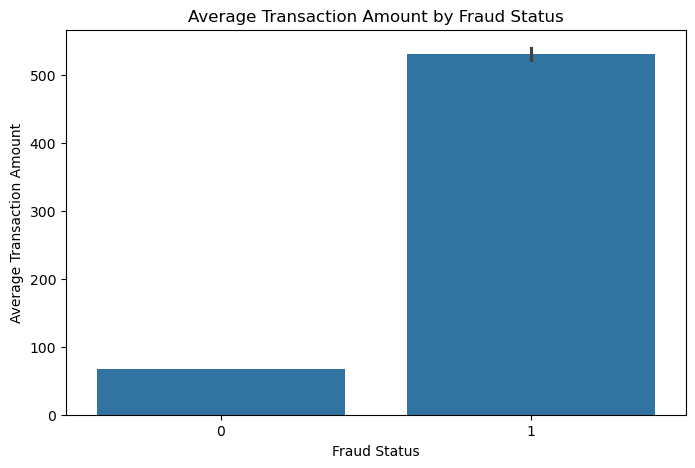

In [27]:
# Barplot

plt.figure(figsize=(8,5))

sns.barplot(
    x="is_fraud",
    y="amt",
    data=train
)

plt.title("Average Transaction Amount by Fraud Status")
plt.xlabel("Fraud Status")
plt.ylabel("Average Transaction Amount")
plt.show()

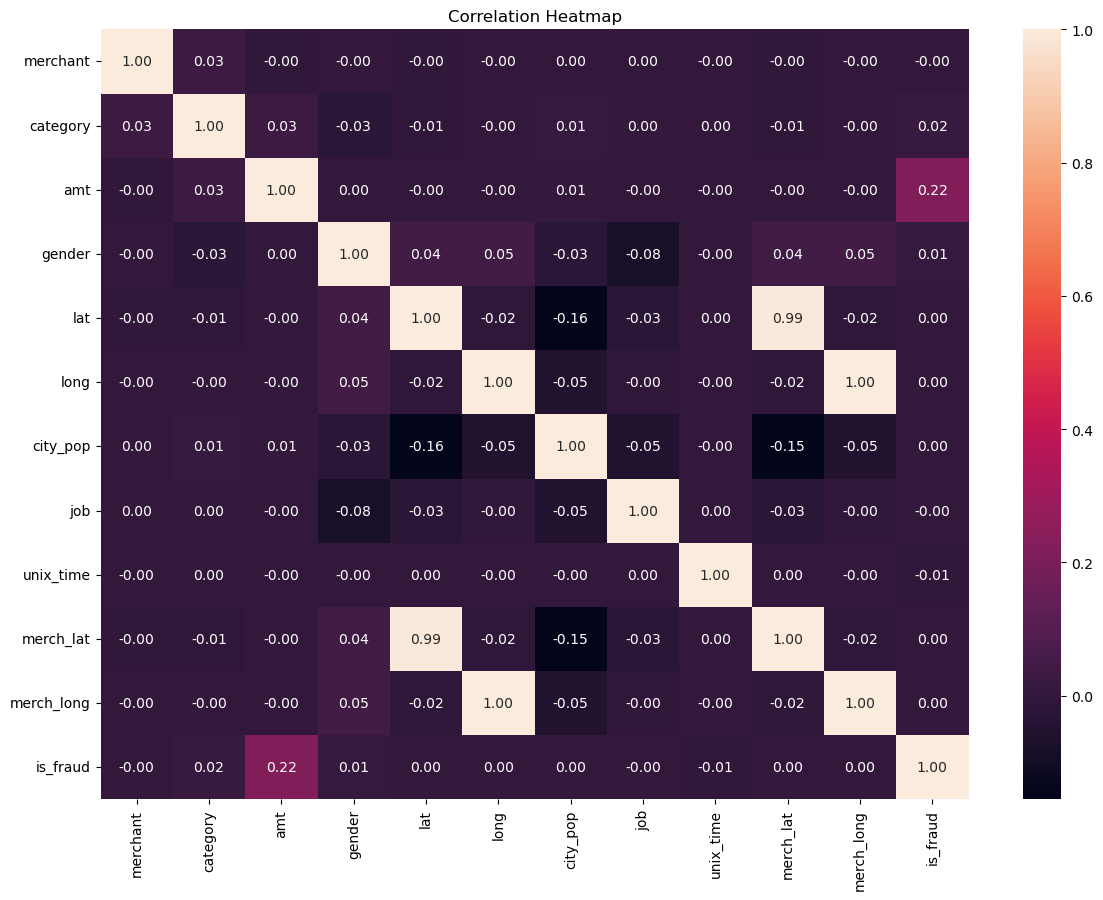

In [28]:
# Heatmap

plt.figure(figsize=(14,10))

sns.heatmap(
    train.corr(numeric_only=True),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

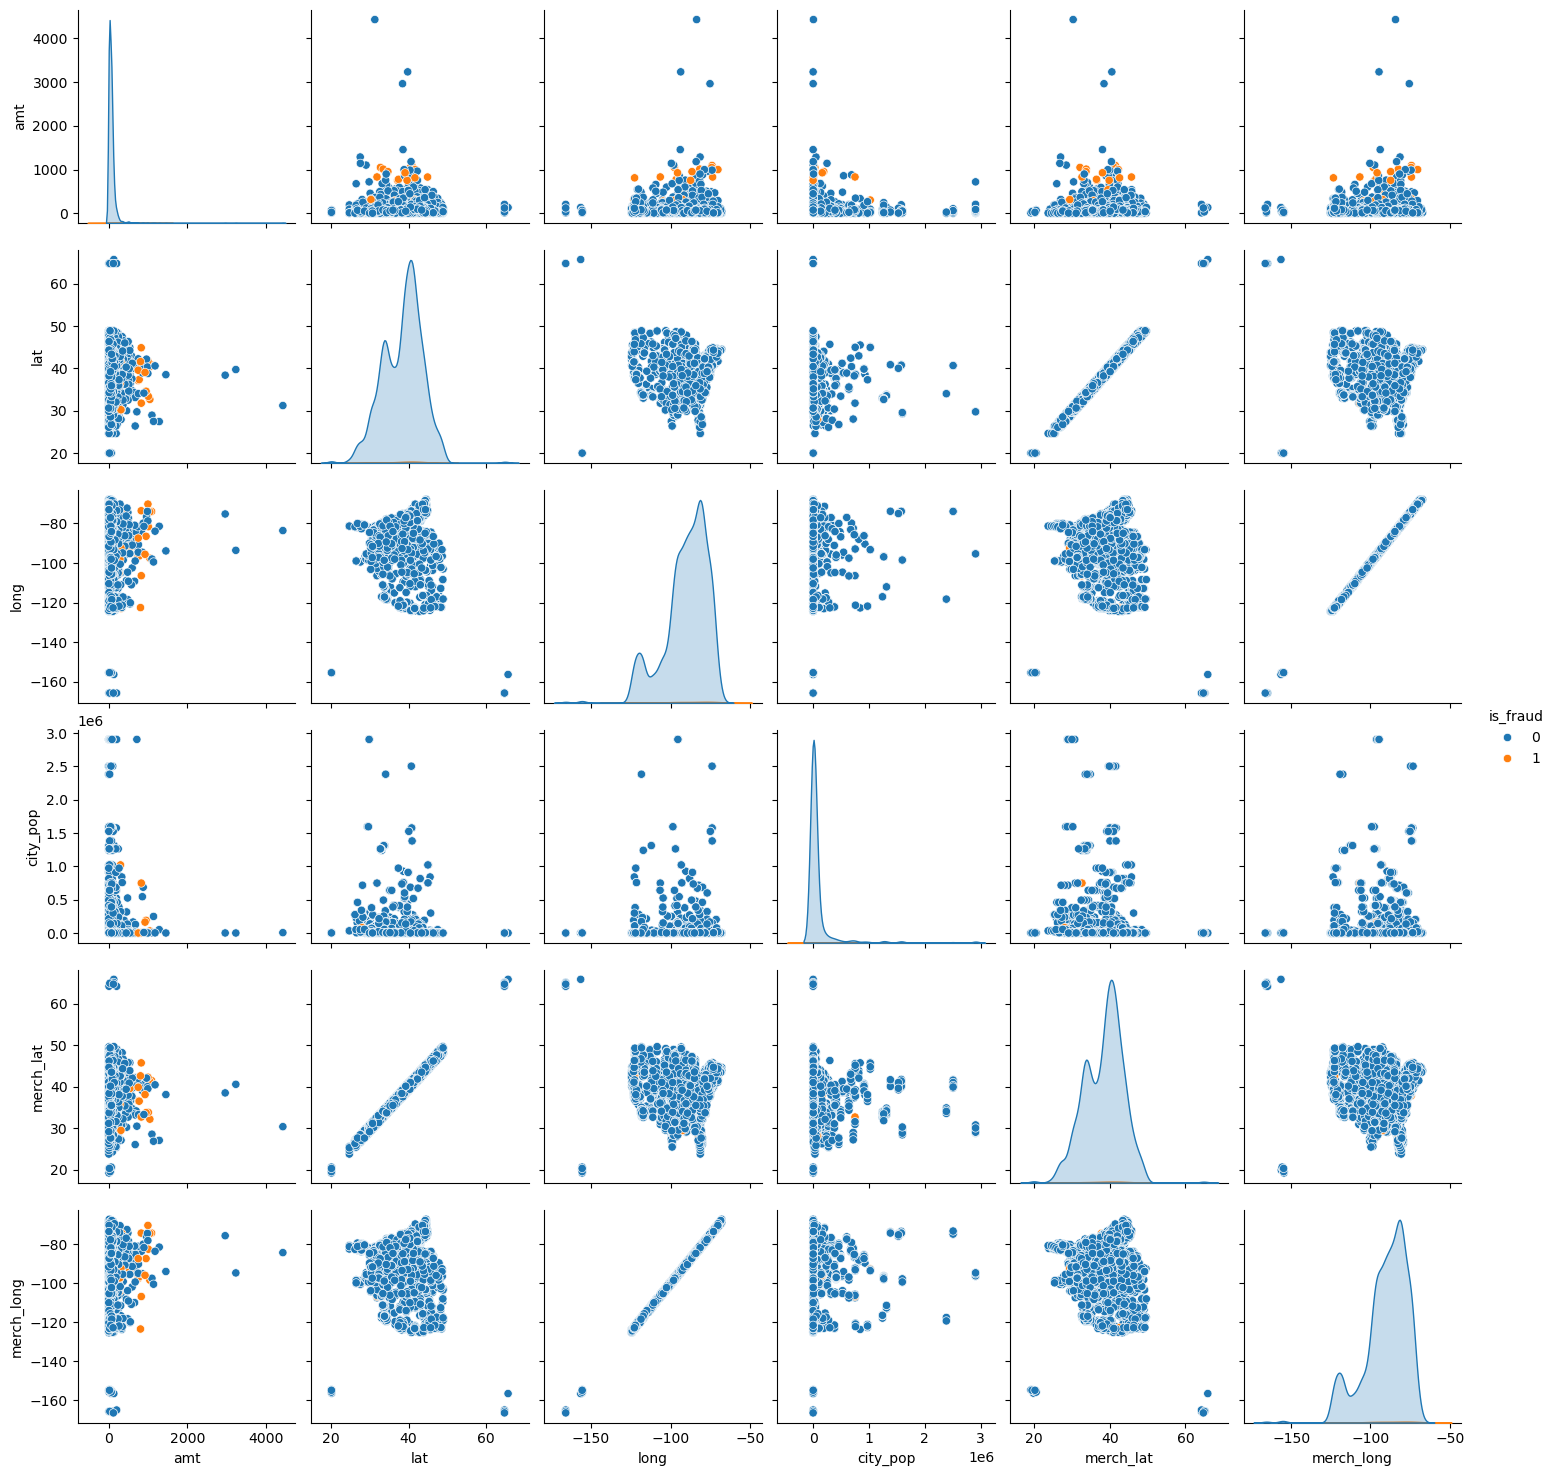

In [29]:
# Pairplot

pairplot_columns = [
    "amt",
    "lat",
    "long",
    "city_pop",
    "merch_lat",
    "merch_long",
    "is_fraud"
]

pairplot_data = train[pairplot_columns].sample(
    min(5000, len(train)),
    random_state=42
)

sns.pairplot(
    pairplot_data,
    hue="is_fraud"
)

plt.show()

In [30]:
# Separate features and target

X_train = train.drop("is_fraud", axis=1)
y_train = train["is_fraud"]

X_test = test.drop("is_fraud", axis=1)
y_test = test["is_fraud"]

In [31]:
X_train_split, X_validation, y_train_split, y_validation = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

In [32]:
# Feature Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_split)
X_validation_scaled = scaler.transform(X_validation)
X_test_scaled = scaler.transform(X_test)

In [33]:
# Model 1 - Logistic Regression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train_split
)

y_pred_logistic = logistic_model.predict(X_test_scaled)

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred_logistic))

print("Logistic Regression F1 Score:",
      f1_score(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.9672046483924429
Logistic Regression F1 Score: 0.14856341976173792


In [34]:
# Model 2 - Decision Tree

decision_tree_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

decision_tree_model.fit(
    X_train_split,
    y_train_split
)

y_pred_tree = decision_tree_model.predict(X_test)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Decision Tree F1 Score:",
      f1_score(y_test, y_pred_tree))

Decision Tree Accuracy: 0.9965648106327119
Decision Tree F1 Score: 0.3803959753326842


In [35]:
# Model 3 - Random Forest

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_split,
    y_train_split
)

y_pred_rf = random_forest_model.predict(X_test)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Random Forest F1 Score:",
      f1_score(y_test, y_pred_rf))

Random Forest Accuracy: 0.996989485693309
Random Forest F1 Score: 0.36652783036728515


In [36]:
# Model 4 - Gradient Boosting

gradient_model = GradientBoostingClassifier(
    random_state=42
)

gradient_model.fit(
    X_train_split,
    y_train_split
)

y_pred_gradient = gradient_model.predict(X_test)

print("Gradient Boosting Accuracy:",
      accuracy_score(y_test, y_pred_gradient))

print("Gradient Boosting F1 Score:",
      f1_score(y_test, y_pred_gradient))

Gradient Boosting Accuracy: 0.9974501501658212
Gradient Boosting F1 Score: 0.6198014488865039


In [37]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gradient)
    ],
    
    "F1 Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_gradient)
    ]
})

results

,Model,Accuracy,F1 Score
0,Logistic Regression,0.967205,0.148563
1,Decision Tree,0.996565,0.380396
2,Random Forest,0.996989,0.366528
3,Gradient Boosting,0.997450,0.619801


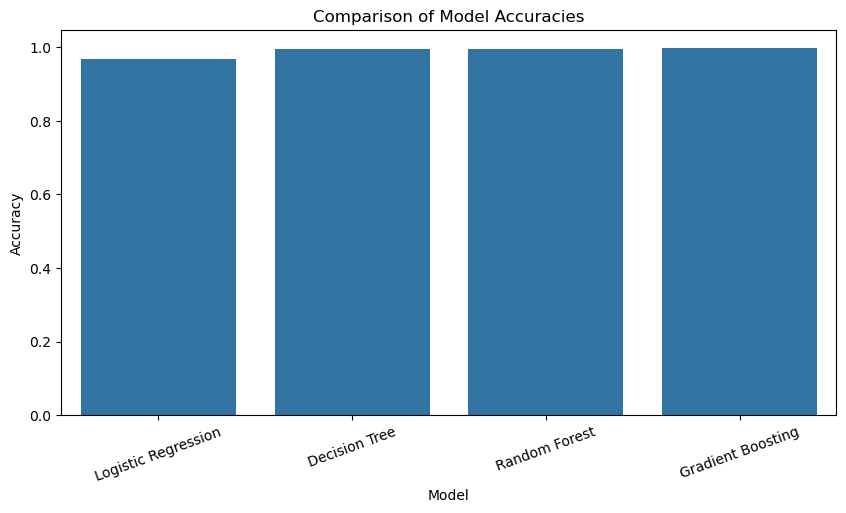

In [38]:
# Accuracy Comparison

plt.figure(figsize=(10,5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Model Accuracies")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=20)
plt.show()

In [39]:
# Logistic Regression

print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_logistic))
print("Accuracy Score:",
      accuracy_score(y_test, y_pred_logistic))
print("F1 Score:",
      f1_score(y_test, y_pred_logistic))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

           0       1.00      0.97      0.98    553574
           1       0.08      0.74      0.15      2145

    accuracy                           0.97    555719
   macro avg       0.54      0.85      0.57    555719
weighted avg       1.00      0.97      0.98    555719

Accuracy Score: 0.9672046483924429
F1 Score: 0.14856341976173792


In [40]:
# Decision Tree

print("DECISION TREE")
print(classification_report(y_test, y_pred_tree))
print("Accuracy Score:",
      accuracy_score(y_test, y_pred_tree))
print("F1 Score:",
      f1_score(y_test, y_pred_tree))

DECISION TREE
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.63      0.27      0.38      2145

    accuracy                           1.00    555719
   macro avg       0.81      0.64      0.69    555719
weighted avg       1.00      1.00      1.00    555719

Accuracy Score: 0.9965648106327119
F1 Score: 0.3803959753326842


In [41]:
# Random Forest

print("RANDOM FOREST")
print(classification_report(y_test, y_pred_rf))
print("Accuracy Score:",
      accuracy_score(y_test, y_pred_rf))
print("F1 Score:",
      f1_score(y_test, y_pred_rf))

RANDOM FOREST
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.98      0.23      0.37      2145

    accuracy                           1.00    555719
   macro avg       0.99      0.61      0.68    555719
weighted avg       1.00      1.00      1.00    555719

Accuracy Score: 0.996989485693309
F1 Score: 0.36652783036728515


In [42]:
# Gradient Boosting

print("GRADIENT BOOSTING")
print(classification_report(y_test, y_pred_gradient))
print("Accuracy Score:",
      accuracy_score(y_test, y_pred_gradient))
print("F1 Score:",
      f1_score(y_test, y_pred_gradient))

GRADIENT BOOSTING
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    553574
           1       0.73      0.54      0.62      2145

    accuracy                           1.00    555719
   macro avg       0.86      0.77      0.81    555719
weighted avg       1.00      1.00      1.00    555719

Accuracy Score: 0.9974501501658212
F1 Score: 0.6198014488865039


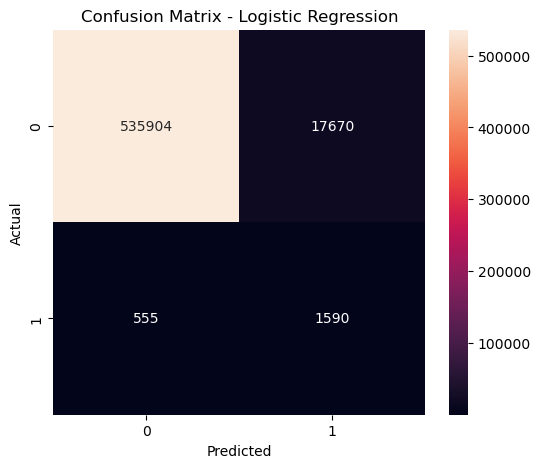

In [43]:
# Logistic Regression

cm = confusion_matrix(y_test, y_pred_logistic)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

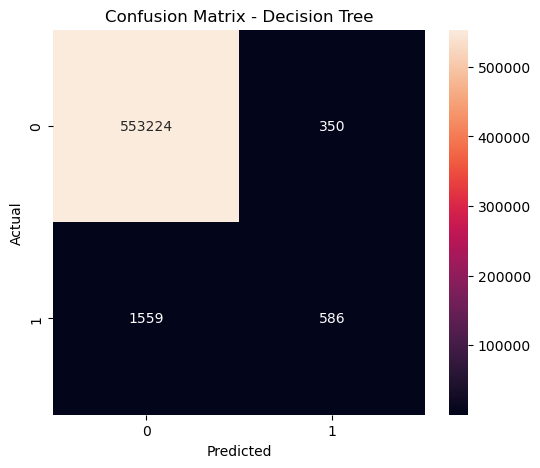

In [44]:
# Decision Tree

cm = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

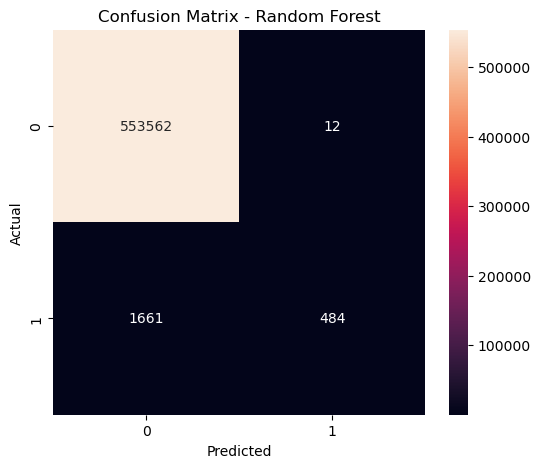

In [45]:
# Random Forest

cm = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

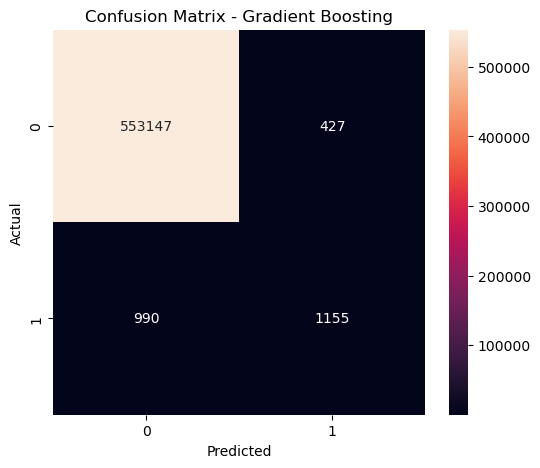

In [46]:
# Gradient Boosting

cm = confusion_matrix(y_test, y_pred_gradient)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title("Confusion Matrix - Gradient Boosting")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()